In [112]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (10,6)

In [113]:
pd.set_option('display.max.rows', 1000)

In [114]:
df = pd.read_csv(r'C:\Users\karti\Desktop\Proj-3\movies.csv')

In [115]:
df.head()


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [116]:
# looking for missing values
for col in df.columns :
    percent_missing = np.sum(df[col].isnull())
    print(f'{col} - {percent_missing}')

# df.groupby(by=['name', 'rating','company']).size().loc[lambda x: x > 1]
# checked if same movie listed twice but found them different 


name - 0
rating - 77
genre - 0
year - 0
released - 2
score - 3
votes - 3
director - 0
writer - 3
star - 1
country - 3
budget - 2171
gross - 189
company - 17
runtime - 4


In [117]:
df['rating'].unique()
# df[df['rating'] == 'Not Rated'].count()
# df[df['rating'] == 'Unrated'].count()

<StringArray>
[        'R',        'PG',         'G',         nan, 'Not Rated',     'NC-17',
  'Approved',     'TV-PG',     'PG-13',   'Unrated',         'X',     'TV-MA',
     'TV-14']
Length: 13, dtype: str

In [118]:
df['rating'] = df['rating'].replace('Unrated', 'Not Rated') 
df['rating'] = df['rating'].fillna('Not Rated') 

In [119]:
df['budget']=df.groupby(by='genre')[['budget']].transform(lambda x : x.fillna(x.median()))

# df.groupby(by='genre')[['genre','gross']].apply(lambda x : print(x['genre'], x['gross'].isnull().sum()))
# checking nulls in each genre

df['gross']=df.groupby(by='genre')[['gross']].transform(lambda x : x.fillna(x.median()) )

In [120]:
for col in df.columns :
    print(col, df[col].isnull().sum())

name 0
rating 0
genre 0
year 0
released 2
score 3
votes 3
director 0
writer 3
star 1
country 3
budget 4
gross 1
company 17
runtime 4


In [121]:
# now we have no major rows with nulls so removing them
df.dropna(inplace=True)

for col in df.columns :
    print(col, df[col].isnull().sum())

name 0
rating 0
genre 0
year 0
released 0
score 0
votes 0
director 0
writer 0
star 0
country 0
budget 0
gross 0
company 0
runtime 0


In [ ]:
# standardizing the data

In [122]:
df.head(2)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0


In [123]:
df.dtypes

name            str
rating          str
genre           str
year          int64
released        str
score       float64
votes       float64
director        str
writer          str
star            str
country         str
budget      float64
gross       float64
company         str
runtime     float64
dtype: object

In [124]:
df[['gross','votes', 'budget','runtime']] = df[['gross','votes', 'budget','runtime']].astype('int64')

In [ ]:
df['year_corrected']=df['released'].str.split(',').str[1].str.split().str[0]
# df[df['year_corrected'].isnull()]
# formats are different in some rows so there  are nulls

In [125]:
df['year_corrected']=df['released'].str.extract(r'(\d{4})')
df['year_corrected']= df['year_corrected'].astype('int64')

In [126]:
# verify if released year col is same as year col 
(df['year_corrected'] == df['year']).all() 
# false
df[df['year_corrected'] != df['year']].head(3)
# we can see we had incorrect year for some rows

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_corrected
8,Superman II,PG,Action,1980,"June 19, 1981 (United States)",6.8,101000,Richard Lester,Jerry Siegel,Gene Hackman,United States,54000000,108185706,Dovemead Films,127,1981
11,The Gods Must Be Crazy,PG,Adventure,1980,"October 26, 1984 (United States)",7.3,54000,Jamie Uys,Jamie Uys,N!xau,South Africa,5000000,30031783,C.A.T. Films,109,1984
21,Heaven's Gate,R,Adventure,1980,"April 24, 1981 (United States)",6.8,14000,Michael Cimino,Michael Cimino,Kris Kristofferson,United States,44000000,3484523,Partisan Productions,219,1981


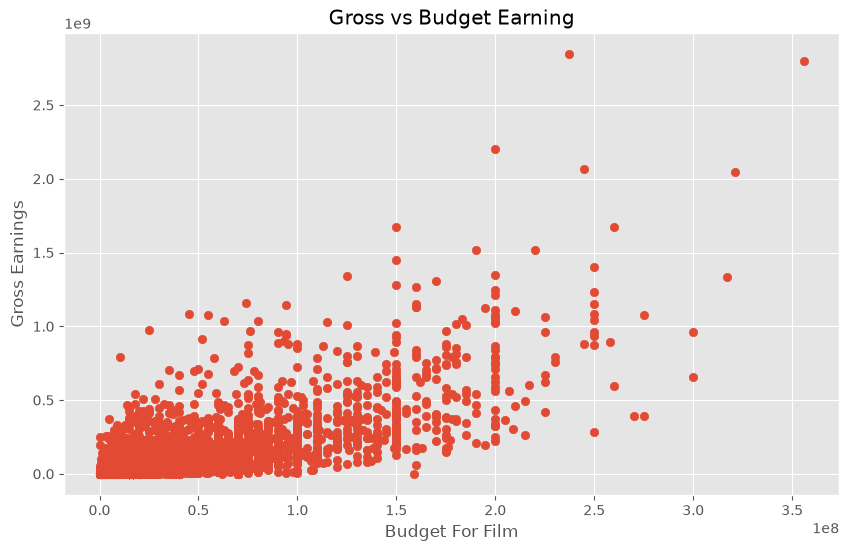

In [127]:
# budget might have high correalation with gross, the more budget the more they earn

plt.scatter(x=df['budget'], y=df['gross'])
plt.title('Gross vs Budget Earning')
plt.xlabel('Budget For Film')
plt.ylabel('Gross Earnings')
plt.show()

# showing positive correlation as points form an upward trend and how tightly the points cluster around a straight line shows strong correlation
# while wide dispersion indicates a weak correlation

In [ ]:
# df.sort_values(by='budget', ascending=False).head(3)

<Axes: xlabel='budget', ylabel='gross'>

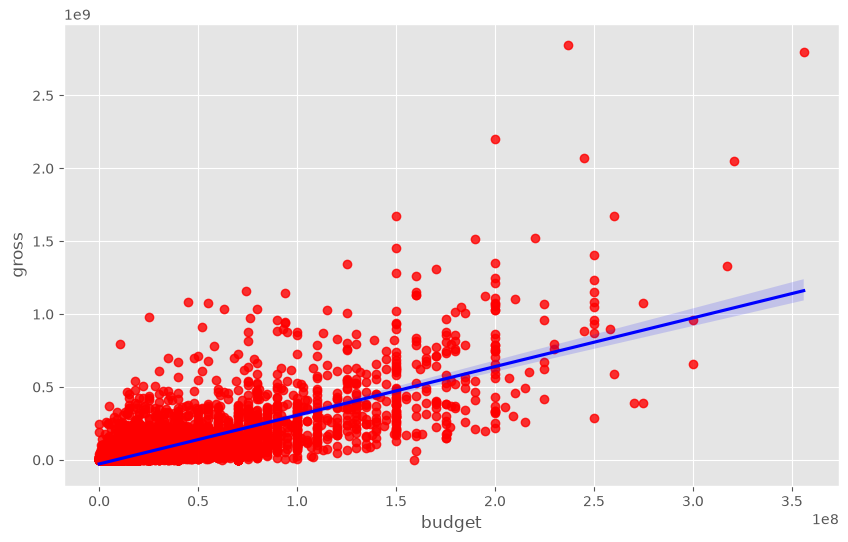

In [128]:
# we have to determine if they are correlated by values too or not, as visually it just seems. so using regression plot in sns
# reg line is A regression line (or trendline) is a straight line drawn on a scatter plot that best summarizes the linear relationship between two variables.  It gives a predicted value of the dependent variable (y) for any given value of the independent variable (x)
sns.regplot(x='budget', y='gross',data=df, scatter_kws={"color":"red"}, line_kws={"color":"blue"})

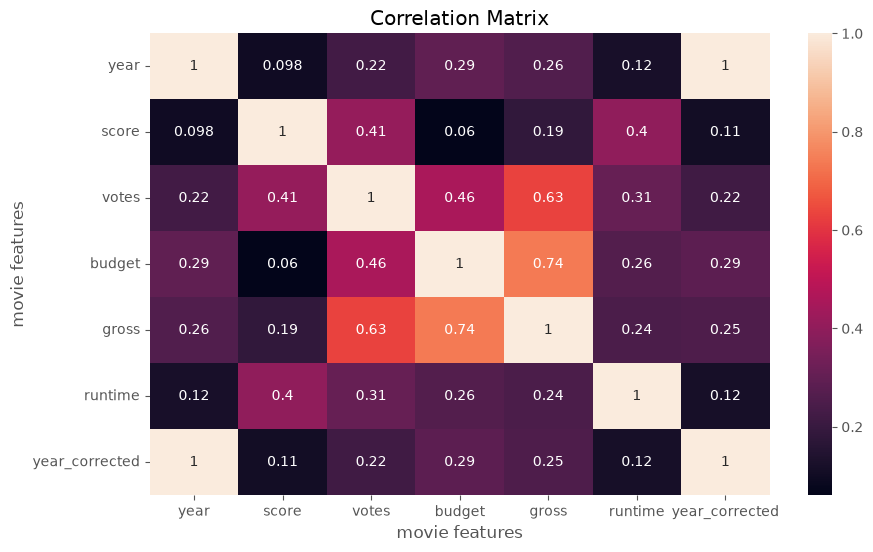

In [129]:
correlation_matrix = df.corr(numeric_only=True)   

sns.heatmap(correlation_matrix, annot = True)
plt.title('Correlation Matrix')
plt.xlabel('movie features')
plt.ylabel('movie features')
plt.show()

In [130]:
df.sort_values(by='gross', ascending=False, inplace=True)

In [131]:
# to see correlation between company and gross, we would need numeric values so converting every company col name to their 
# any specific number code like we do in dense rank..... cat.codes assigns any random number to names

numeric_df = df.copy()
# converting every col cells to any specific num 
for col in numeric_df.columns:
    if(numeric_df[col].dtype == 'str') :
         numeric_df[col] = numeric_df[col].astype('category')
         numeric_df[col] = numeric_df[col].cat.codes

numeric_df

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_corrected
5445,531,5,0,2009,693,7.8,1100000,1152,1772,2321,55,237000000,2847246203,2242,162,2009
7445,533,5,0,2019,181,8.4,903000,161,738,2228,55,356000000,2797501328,1595,181,2019
3045,6869,5,6,1997,701,7.8,1100000,1152,1772,1586,55,200000000,2201647264,2242,194,1997
6663,5124,5,0,2015,695,7.8,876000,1122,2539,519,55,245000000,2069521700,1529,138,2015
7244,534,5,0,2018,190,8.4,897000,161,738,2228,55,321000000,2048359754,1595,149,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3818,3346,6,4,2000,1115,6.5,5200,728,1117,2306,54,17000000,1400,474,103,2001
7625,6694,3,4,2019,1145,5.7,320,2531,2554,1904,55,17000000,790,2297,104,2019
7580,4646,3,5,2019,1830,5.2,735,1439,2194,2265,55,15000000,682,1981,93,2020
2417,3392,3,6,1993,84,7.3,5100,33,1712,2549,27,11900000,596,791,134,1993


In [132]:
df
# you can compare repeating names that have same number assigned

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_corrected
5445,Avatar,PG-13,Action,2009,"December 18, 2009 (United States)",7.8,1100000,James Cameron,James Cameron,Sam Worthington,United States,237000000,2847246203,Twentieth Century Fox,162,2009
7445,Avengers: Endgame,PG-13,Action,2019,"April 26, 2019 (United States)",8.4,903000,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,356000000,2797501328,Marvel Studios,181,2019
3045,Titanic,PG-13,Drama,1997,"December 19, 1997 (United States)",7.8,1100000,James Cameron,James Cameron,Leonardo DiCaprio,United States,200000000,2201647264,Twentieth Century Fox,194,1997
6663,Star Wars: Episode VII - The Force Awakens,PG-13,Action,2015,"December 18, 2015 (United States)",7.8,876000,J.J. Abrams,Lawrence Kasdan,Daisy Ridley,United States,245000000,2069521700,Lucasfilm,138,2015
7244,Avengers: Infinity War,PG-13,Action,2018,"April 27, 2018 (United States)",8.4,897000,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,321000000,2048359754,Marvel Studios,149,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3818,"Love, Honor and Obey",R,Comedy,2000,"February 9, 2001 (United States)",6.5,5200,Dominic Anciano,Dominic Anciano,Sadie Frost,United Kingdom,17000000,1400,British Broadcasting Corporation (BBC),103,2001
7625,The Untold Story,Not Rated,Comedy,2019,"January 11, 2019 (United States)",5.7,320,Shane Stanley,Lee Stanley,Miko Hughes,United States,17000000,790,Visual Arts Entertainment,104,2019
7580,Run with the Hunted,Not Rated,Crime,2019,"June 26, 2020 (United States)",5.2,735,John Swab,John Swab,Ron Perlman,United States,15000000,682,Roxwell Films,93,2020
2417,Madadayo,Not Rated,Drama,1993,"April 17, 1993 (Japan)",7.3,5100,Akira Kurosawa,Ishirô Honda,Tatsuo Matsumura,Japan,11900000,596,DENTSU Music And Entertainment,134,1993


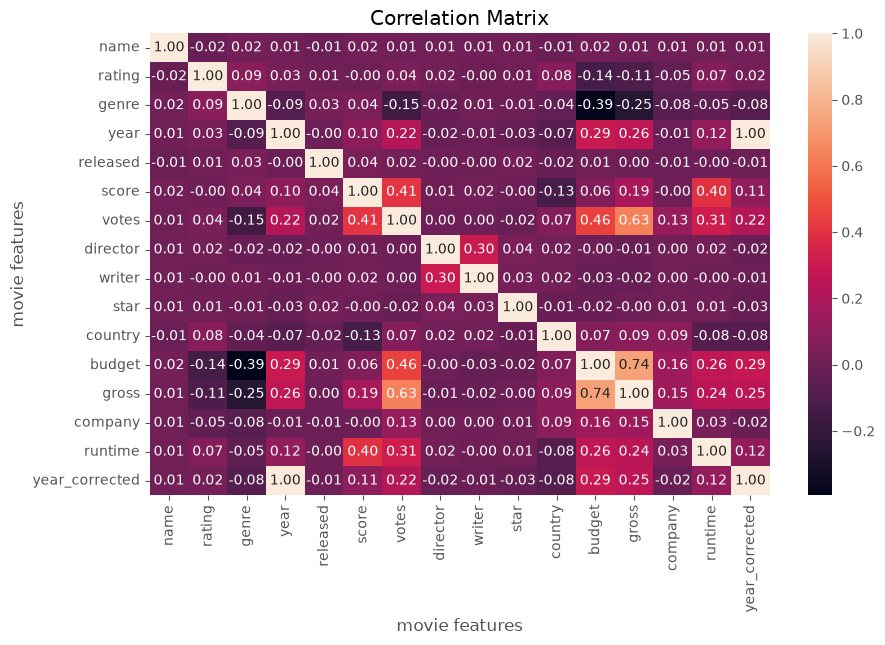

In [133]:
correlation_matrix = numeric_df.corr()   

sns.heatmap(correlation_matrix, annot = True,fmt='.2f' )
plt.title('Correlation Matrix')
plt.xlabel('movie features')
plt.ylabel('movie features')

plt.show()

In [134]:
corr_matrix = numeric_df.corr()
corr_pairs = corr_matrix.unstack()
corr_pairs

name            name              1.000000
                rating           -0.018016
                genre             0.016887
                year              0.012480
                released         -0.010767
                score             0.017062
                votes             0.012949
                director          0.008688
                writer            0.009445
                star              0.006189
                country          -0.011167
                budget            0.019811
                gross             0.006814
                company           0.010376
                runtime           0.011261
                year_corrected    0.011880
rating          name             -0.018016
                rating            1.000000
                genre             0.086996
                year              0.026375
                released          0.010423
                score            -0.002640
                votes             0.038866
           

In [135]:
sorted_pairs = corr_pairs.sort_values()
sorted_pairs

genre           budget           -0.394248
budget          genre            -0.394248
gross           genre            -0.247358
genre           gross            -0.247358
                votes            -0.153729
votes           genre            -0.153729
rating          budget           -0.137920
budget          rating           -0.137920
country         score            -0.133110
score           country          -0.133110
rating          gross            -0.108635
gross           rating           -0.108635
year            genre            -0.085601
genre           year             -0.085601
year_corrected  genre            -0.081673
genre           year_corrected   -0.081673
country         runtime          -0.080103
runtime         country          -0.080103
year_corrected  country          -0.079934
country         year_corrected   -0.079934
genre           company          -0.075345
company         genre            -0.075345
country         year             -0.069303
year       

In [136]:
high_corr = sorted_pairs[(sorted_pairs) > 0.5]
high_corr

# budget and votes have the highest corr to gross earnings

gross           votes             0.631785
votes           gross             0.631785
gross           budget            0.738030
budget          gross             0.738030
year            year_corrected    0.997398
year_corrected  year              0.997398
director        director          1.000000
votes           votes             1.000000
released        released          1.000000
score           score             1.000000
rating          rating            1.000000
name            name              1.000000
genre           genre             1.000000
year            year              1.000000
budget          budget            1.000000
country         country           1.000000
writer          writer            1.000000
star            star              1.000000
company         company           1.000000
gross           gross             1.000000
runtime         runtime           1.000000
year_corrected  year_corrected    1.000000
dtype: float64